# Dónde pierden tiempo los buses de Bogotá · TransMilenio + Ray

**Proyecto final 4.1 · Computación Paralela · MCIC, Universidad Distrital, 2026-3**
Juan Felipe Rodríguez Galindo y Carlos Stiven Mora Hoyos

Los buses de Bogotá son cada año más lentos: la velocidad zonal en el pico de la mañana bajó de 26,8 a 24,9 km/h entre
2023 y 2024 (análisis de la Subgerencia Económica de TransMilenio, dic. 2024) y la demanda zonal cayó. La ciudad decide
carriles exclusivos y prioridad semafórica sin un mapa público de dónde y cuándo se frenan los buses. Nueva York y
California publican ese mapa a partir de las posiciones de los buses (ver `investigacion/reports/`). Bogotá abrió su
feed GTFS-Realtime en noviembre de 2026; este cuaderno lo analiza en histórico, con Ray, y entrega tres soluciones:

1. **Atlas de velocidad y retraso** por tramo de 500 m y hora, con un ranking de dónde priorizar el bus.
2. **Cuánto reservar** entre dos paradas para llegar a tiempo 19 de cada 20 veces, y dónde el horario se queda corto.
3. **Brecha de accesibilidad al empleo** entre el horario y la operación observada, por estrato.

No se usan intervalos entre buses (headways): ese es el tema de la tesis.

Las celdas leen los resultados de `resultados/`, que produce el pipeline (`pipeline/`). Para regenerarlos, ver el
README; la corrida completa tarda cerca de una hora en 6 núcleos.

In [1]:
import json, sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, "pipeline")
from tm import nucleo, sintetico
R = Path("resultados")
leer = lambda n: json.loads((R / n).read_text())
tiempos = pd.DataFrame([json.loads(l) for f in ("tiempos.jsonl", "tiempos_local.jsonl") if (R / f).exists()
                        for l in (R / f).read_text().splitlines() if l.strip()])
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Los datos y su calidad

El archivo guarda el feed de posiciones cada 20 s desde el 11 de noviembre de 2026
([`Fozzy3/parallel-computing-final`](https://github.com/Fozzy3/parallel-computing-final)). Se analizan los días de
servicio del 12 al 23 de noviembre (el 11 está incompleto). El ETL descarta reportes con más de 5 min de antigüedad
(buses «zombis» y congelamientos del feed).

reportes: 80.9 M · duplicados por día: 22–31 % · edad mediana del reporte: 49 s


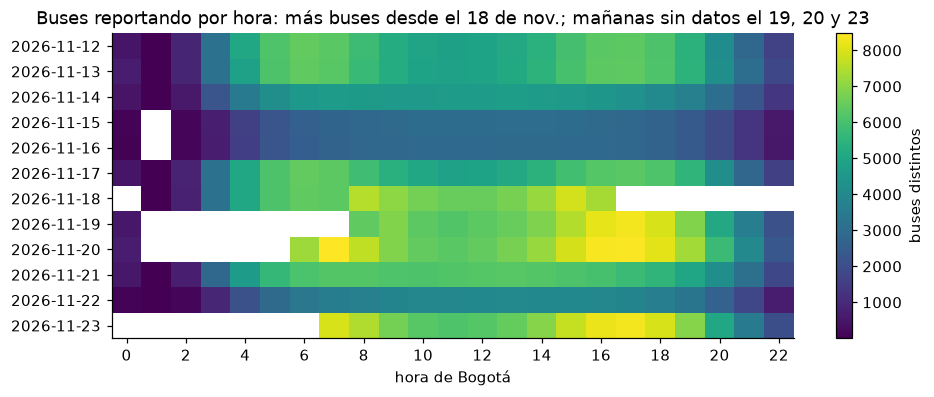

In [2]:
cal = pd.read_csv(R / "calidad.csv")
cal = cal[cal.dia.between("2026-11-12", "2026-11-23")]
print(f"reportes: {cal.reportes.sum()/1e6:.1f} M · duplicados por día: {cal.groupby('dia').duplicados_pct.median().min():.0f}–{cal.groupby('dia').duplicados_pct.median().max():.0f} % · edad mediana del reporte: {cal.edad_mediana_s.median():.0f} s")
m = cal.pivot(index="dia", columns="hora", values="buses")
fig, ax = plt.subplots(figsize=(10, 3.6))
im = ax.imshow(m, aspect="auto", cmap="viridis"); fig.colorbar(im, label="buses distintos")
ax.set_yticks(range(len(m)), m.index); ax.set_xticks(range(0, 24, 2), range(0, 24, 2)); ax.set_xlabel("hora de Bogotá")
ax.set_title("Buses reportando por hora: más buses desde el 18 de nov.; mañanas sin datos el 19, 20 y 23"); plt.show()

## 2. El pipeline en Ray

| Etapa | Qué hace | Paralelismo |
|---|---|---|
| `etl` | `.pb.gz` → Parquet por (día, `crc32(vehicle_id) % 64`) | Ray Data: un archivo no depende de otro |
| `recorridos` | emparejar cada bus con su ruta, cortar pasadas, tiempo por tramo de 500 m | Ray Core: una tarea por día × partición; geometrías una vez en el object store |
| `tramos` | velocidad p20/p50/p80 y retraso frente al flujo libre | una tarea por cubo de rutas (32) |
| `confiabilidad` | tiempos en paradas, pares, percentiles, horario, walk-forward | una tarea por cubo de rutas |

Dos cosas del GTFS obligan a cambiar el emparejamiento del proyecto 4: cada ruta tiene **un solo shape** y muchas van
y vuelven por la misma calle, así que el bus se empareja solo con los segmentos que van en su sentido de marcha; y la
pasada se corta si el bus avanza más de 90 km/h (el emparejamiento saltó), retrocede más de 200 m o pasa más de 10 min
detenido (espera en terminal). El kernel caro es la proyección de cada punto sobre su ruta: O(n·m) por bus.

In [3]:
import inspect
print(inspect.getsource(nucleo.emparejar))

def emparejar(p: np.ndarray, geo) -> tuple:
    """Map-matching de puntos consecutivos de un bus (n,2) sobre su ruta. Devuelve (s, desvío) en metros; s es NaN
    si el punto queda a más de MAX_DESVIO. Solo cuentan los segmentos que van en el sentido de marcha del bus: así
    una ruta de ida y vuelta por la misma calle no confunde la ida con la vuelta. Costo O(n·m): el kernel caro.
    ponytail: el sentido no separa un shape que pasa dos veces por la misma calle en el mismo sentido; si aparece,
    el siguiente paso es un HMM (Viterbi) con continuidad de s."""
    q, acum = geo
    a, ab = q[:-1], np.diff(q, axis=0)
    L2 = np.maximum((ab ** 2).sum(1), 1e-9)
    u = rumbo(p)
    con_rumbo = np.hypot(*u.T) > 0
    s, desvio = np.full(len(p), np.nan), np.full(len(p), np.inf)
    for i0 in range(0, len(p), 400):  # por bloques: acota la memoria de la matriz n×m
        sl = slice(i0, i0 + 400)
        ap = p[sl, None, :] - a[None]
        t = np.clip((ap * ab[None]).sum(2) / L2, 0.0, 1.

## 3. Validación

In [4]:
e = sintetico.errores(range(200))
print(f"Trayectorias sintéticas con reportes cada 52 s y ±10 m de ruido ({e.n} tramos):")
print(f"  sesgo agregado {e.sesgo_rel*100:+.1f} % · error mediano {e.mediana_abs_rel*100:.1f} % · p90 {e.p90_abs_rel*100:.1f} %")
v = leer("validacion.json")
print("\nVelocidad comercial medida frente a la oficial de 2024:")
print(pd.DataFrame(v["magnitudes_vs_2024"]).T)
for g in ("mixto", "exclusivo"):
    s = v[f"estabilidad_{g}"]
    print(f"\nEstabilidad del ranking {g}: Spearman {s['spearman_top200']} · {s['solape_top20']} de 20 peores celdas se repiten entre mitades")

Trayectorias sintéticas con reportes cada 52 s y ±10 m de ruido (3601 tramos):
  sesgo agregado +0.5 % · error mediano 8.4 % · p90 21.8 %

Velocidad comercial medida frente a la oficial de 2024:
             medida  oficial  dif_rel
troncal        21.8     25.2   -0.135
dual           17.9     19.8   -0.096
alimentador    14.3     17.5   -0.183

Estabilidad del ranking mixto: Spearman 0.629 · 10 de 20 peores celdas se repiten entre mitades

Estabilidad del ranking exclusivo: Spearman 0.753 · 12 de 20 peores celdas se repiten entre mitades


## 4. Proyecto 1 · Dónde se frenan los buses

             velocidad comercial (km/h)  retraso (bus-horas por día hábil)
alimentador                        14.3                             1596.6
dual                               17.9                              927.6
troncal                            21.8                             3865.4
zonal                              14.3                            29478.1


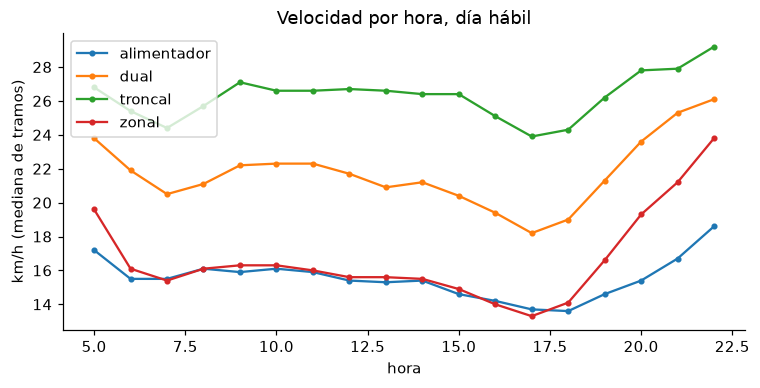

In [5]:
res = leer("resumen.json")
print(pd.DataFrame({"velocidad comercial (km/h)": res["velocidad_comercial"],
                    "retraso (bus-horas por día hábil)": res["bus_horas_retraso_dia_habil"]}).round(1))
fig, ax = plt.subplots(figsize=(8, 3.5))
for s, d in res["v_p50_por_hora"].items():
    d = {int(k): v for k, v in d.items() if 5 <= int(k) <= 22}; ax.plot(list(d), list(d.values()), marker="o", ms=3, label=s)
ax.set_xlabel("hora"); ax.set_ylabel("km/h (mediana de tramos)"); ax.legend(); ax.set_title("Velocidad por hora, día hábil"); plt.show()

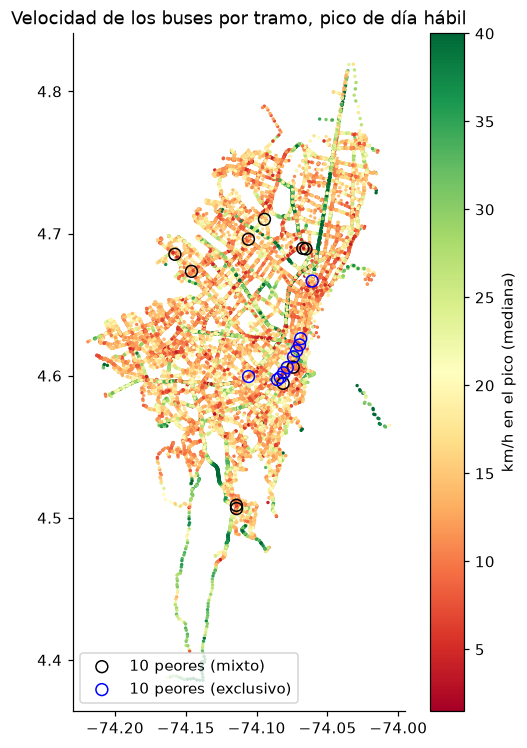

In [6]:
t = pd.read_parquet(R / "tramos.parquet")
p = t[(t.tipo_dia == "laboral") & t.hora.isin([6, 7, 17, 18])].groupby(["route_id", "tramo"]).agg(lon=("lon", "first"), lat=("lat", "first"), v=("v_p50", "median")).reset_index()
fig, ax = plt.subplots(figsize=(6, 8))
sc = ax.scatter(p.lon, p.lat, c=p.v.clip(0, 40), s=1.5, cmap="RdYlGn"); fig.colorbar(sc, label="km/h en el pico (mediana)")
for g, c in (("mixto", "k"), ("exclusivo", "b")):
    rk = pd.read_csv(R / f"ranking_{g}.csv").head(10); ax.scatter(rk.lon, rk.lat, s=60, facecolors="none", edgecolors=c, label=f"10 peores ({g})")
ax.set_aspect(1 / np.cos(np.radians(4.65))); ax.legend(loc="lower left"); ax.set_title("Velocidad de los buses por tramo, pico de día hábil"); plt.show()

In [7]:
for g in ("mixto", "exclusivo"):
    print(f"\n== Ranking {g}: bus-horas perdidas por día hábil frente al flujo libre ==")
    print(pd.read_csv(R / f"ranking_{g}.csv").head(10)[["retraso_h", "ic_bajo", "ic_alto", "rutas", "rutas_top", "v_p50_pico", "lat", "lon"]].round(2).to_string(index=False))


== Ranking mixto: bus-horas perdidas por día hábil frente al flujo libre ==
 retraso_h  ic_bajo  ic_alto  rutas                   rutas_top  v_p50_pico  lat    lon
     95.95    84.65   105.68     56    3-5 HD717 3-3 HA708 3-10        7.83 4.51 -74.11
     89.19    78.75    97.36     37      5-4 DL219 G147 94 A127        8.82 4.70 -74.11
     76.82    56.47    92.10     32 HA618 T13 GA537 HA600 HA620       10.55 4.61 -74.07
     75.70    63.07    89.98     19    BD237 HC705 634 K305 442        7.87 4.69 -74.07
     70.87    58.81    82.79     29       C131 5-1 60 C147 C127       11.24 4.71 -74.09
     68.24    61.99    74.14     35   KA332 G147 K321 K325 K305       10.04 4.67 -74.15
     66.61    58.85    72.61     26  3-10 HD717 HL723 3-8 HA708        6.81 4.51 -74.11
     65.30    46.26    81.65     28 580 HA618 HA617 GA520 HA725       15.06 4.59 -74.08
     63.69    53.85    75.66     16    HA611 KB326 F404 291 661        8.90 4.69 -74.07
     63.55    49.04    78.58     39   16-7 

**Carriles de la Séptima y la Carrera 13.** No hay datos de antes de los carriles, así que no se puede medir su efecto.
Lo que sí se puede es comparar, para las mismas rutas, la velocidad dentro y fuera del carril. Es descriptivo: los
carriles están en el centro denso.

In [8]:
c = leer("carriles.json")
print(pd.DataFrame({(k, f): {lado: x[lado]["v_p50"] for lado in ("dentro", "fuera")} for k, v in c.items() for f, x in v.items() if f != "rutas"}).T)

                 dentro  fuera
carrera13 pico     12.1   14.1
          valle    11.1   14.7
septima   pico     14.0   14.9
          valle    15.3   15.9


## 5. Proyecto 2 · Cuánto reservar

Colchón típico en el pico (BTI mediano = (p95 − media)/media): {'alimentador': 0.248, 'dual': 0.22, 'troncal': 0.181, 'zonal': 0.209}

Walk-forward: p95 con ['2026-11-12', '2026-11-13', '2026-11-17', '2026-11-18'] → cubre el 87.5 % de 5,622,656 viajes de ['2026-11-19', '2026-11-20', '2026-11-23'] (meta 95 %)


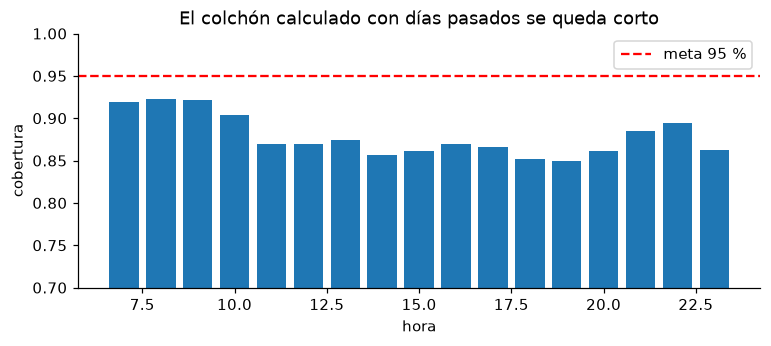


Holgura del horario oficial (día hábil):
             alimentador   dual  troncal  zonal
sobra              0.755  0.263    0.433  0.431
ok                 0.206  0.137    0.144  0.196
corto              0.039  0.598    0.422  0.371
sin_horario        0.000  0.002    0.001  0.002


In [9]:
cf = res["confiabilidad"]
print("Colchón típico en el pico (BTI mediano = (p95 − media)/media):", cf["bti_mediana_pico"])
wf = leer("walkforward.json")
print(f"\nWalk-forward: p95 con {wf['dias_entrena']} → cubre el {wf['cobertura']*100:.1f} % de {wf['viajes_prueba']:,} viajes de {wf['dias_prueba']} (meta 95 %)")
h = {int(k): v for k, v in wf["cobertura_por_hora"].items()}
fig, ax = plt.subplots(figsize=(8, 3)); ax.bar(list(h), list(h.values())); ax.axhline(0.95, color="r", ls="--", label="meta 95 %")
ax.set_ylim(0.7, 1); ax.set_xlabel("hora"); ax.set_ylabel("cobertura"); ax.legend(); ax.set_title("El colchón calculado con días pasados se queda corto"); plt.show()
print("\nHolgura del horario oficial (día hábil):"); print(pd.DataFrame(cf["holgura_dia_habil"]).fillna(0).round(3))

In [10]:
for g in ("exclusivo", "mixto"):
    print(f"\n== Pares menos confiables ({g}, pico de día hábil) ==")
    print(pd.read_csv(R / f"menos_confiables_{g}.csv").head(8).to_string(index=False))


== Pares menos confiables (exclusivo, pico de día hábil) ==
ruta sistema               desde                     hasta  hora  n  p50_min  p95_min  colchon_min  bti  pti holgura
 F26 troncal Calle 100 C - 2 ó 5   Patio Bonito B - 4 ó 6.    18 43    60.17   100.94        40.77 0.55 2.24   sobra
 F26 troncal Calle 127 B - 2 ó 5   Patio Bonito B - 4 ó 6.    18 46    64.58   105.07        40.49 0.51 2.16   sobra
 D81    dual           K7 - CL50 Br. Ciudadela Colsubsidio    17 73    68.16   108.37        40.21 0.54 3.55   corto
 D81    dual           K7 - CL57 Br. Ciudadela Colsubsidio    17 70    65.75   105.72        39.97 0.57 3.66   corto
 F26 troncal    Virrey C - 2 ó 5   Patio Bonito B - 4 ó 6.    18 43    58.01    97.95        39.94 0.56 2.25   sobra
 D81    dual           K7 - CL34 Br. Ciudadela Colsubsidio    17 67    77.25   116.97        39.72 0.49 3.25   corto
 D81    dual         K7  -  CL45 Br. Ciudadela Colsubsidio    17 72    71.79   111.25        39.46 0.52 3.43   corto
 F2

## 6. Proyecto 3 · Accesibilidad al empleo

In [11]:
if (R / "accesibilidad.json").exists():
    a = leer("accesibilidad.json")
    print(f"{a['zonas_origen']} zonas de origen · {a['empleo_total']:,} viajes a trabajar (proxy de empleo) · {a['actores']} actores Ray")
    print("Brecha mediana a 60 min (observado / programado − 1):", a["brecha_mediana_60"])
    print(pd.DataFrame(a["por_estrato"]))
    print("Tiempos (s):", a["tiempos_s"])
else:
    print("Proyecto 3 pendiente: correr pipeline/accesibilidad.py (ver README).")

580 zonas de origen · 2,881,812 viajes a trabajar (proxy de empleo) · 1 actores Ray
Brecha mediana a 60 min (observado / programado − 1): {'observado': 0.161, 'observado_lento': -0.094}
   estrato  zonas  programado_60_pct  observado_60_pct  \
0      1.0     68              10.95             13.76   
1      2.0    183              20.56             22.65   
2      3.0    202              41.18             46.55   
3      4.0     67              51.17             62.34   
4      5.0     29              42.51             51.48   
5      6.0     31              29.30             35.86   

   observado_lento_60_pct  brecha_obs_60  brecha_lento_60  
0                    9.16          0.143           -0.112  
1                   16.95          0.117           -0.142  
2                   35.67          0.171           -0.106  
3                   46.92          0.225           -0.035  
4                   40.54          0.172           -0.052  
5                   30.45          0.158       

## 7. Rendimiento: speedup y Amdahl

secuencial: 1196 s
 cpus  etl  recorridos  tramos  confiabilidad  total  speedup
  1.0 46.4       535.4     8.5          534.1 1124.4      1.1
  2.0 39.0       283.8     4.6          408.6  736.1      1.6
  4.0 29.8       249.3     4.6          275.3  559.0      2.1
  8.0 32.7       199.2     2.9          197.1  431.9      2.8
fracción paralela estimada (Amdahl): p ≈ 0.73 → speedup máximo ≈ 3.7×


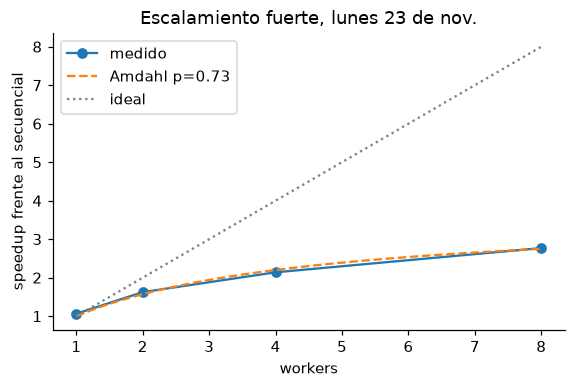


Corrida completa de 12 días, 6 núcleos (s): {'etl': 303.58, 'recorridos': 1925.0, 'tramos': 32.07, 'confiabilidad': 1171.74}


In [12]:
f = tiempos[tiempos.etiqueta == "fuerte-local"].copy()
if len(f) and (f.modo == "secuencial").any():
    f["total"] = f.tiempos.map(lambda d: sum(d.values()))
    for k in ("etl", "recorridos", "tramos", "confiabilidad"):
        f[k] = f.tiempos.map(lambda d: d.get(k))
    base = f[f.modo == "secuencial"].iloc[-1]
    ray = f[f.modo == "ray"].drop_duplicates("cpus", keep="last").sort_values("cpus")
    tabla = ray[["cpus", "etl", "recorridos", "tramos", "confiabilidad", "total"]].assign(speedup=base.total / ray.total)
    print(f"secuencial: {base.total:.0f} s"); print(tabla.round(1).to_string(index=False))
    n, s = ray.cpus.to_numpy(float), base.total / ray.total.to_numpy()
    ps = np.linspace(0, 1, 1001); err = [((1 / ((1 - p) + p / n) - s) ** 2).sum() for p in ps]; p = ps[int(np.argmin(err))]
    print(f"fracción paralela estimada (Amdahl): p ≈ {p:.2f} → speedup máximo ≈ {1/(1-p):.1f}×")
    fig, ax = plt.subplots(figsize=(6, 3.5)); x = np.linspace(1, 8, 50)
    ax.plot(n, s, "o-", label="medido"); ax.plot(x, 1 / ((1 - p) + p / x), "--", label=f"Amdahl p={p:.2f}"); ax.plot(x, x, ":", c="gray", label="ideal")
    ax.set_xlabel("workers"); ax.set_ylabel("speedup frente al secuencial"); ax.legend(); ax.set_title("Escalamiento fuerte, lunes 23 de nov."); plt.show()
else:
    print("Benchmark pendiente: ./pipeline/bench_local.sh")
c12 = tiempos[tiempos.etiqueta.isin(["local-completo", "local-completo-v2"])]
print("\nCorrida completa de 12 días, 6 núcleos (s):", {**c12.iloc[0].tiempos, **c12.iloc[-1].tiempos})

## 8. Conclusiones

- Con el feed abierto de TransMilenio y un pipeline en Ray se puede publicar lo que Nueva York y California ya publican:
  dónde y cuándo se frenan los buses, tramo por tramo, con una validación explícita de su error.
- Los peores puntos de tráfico mixto están en la periferia sur y en el centro; en carril exclusivo, en la Caracas
  central. Son el punto de partida para decidir dónde poner el próximo carril o semáforo prioritario.
- El colchón para llegar a tiempo calculado con días pasados se queda corto (cobertura menor al 95 %): la
  variabilidad entre días es real y hay que comunicarla así.
- Desde una zona de estrato 1 se alcanzan 4 a 5 veces menos empleos en 60 min que desde una de estrato 4. El horario
  oficial es conservador en un día típico, pero en un día lento (p80) los estratos 1 y 2 pierden 11 % a 14 % de acceso
  frente al horario y los altos solo 3 % a 5 %: la variabilidad castiga más a la periferia, como en Fortaleza.
- El paralelismo se justifica por el costo por punto (emparejar cada reporte con su ruta), por la independencia de
  bus-días y cubos de rutas, y por el remuestreo, más que por el volumen bruto. En un portátil de 4 núcleos físicos el
  speedup llega a 2,8× con 8 workers (Amdahl p ≈ 0,73); el ETL no escala (E/S) y los actores de r5py los limita la
  memoria, no los núcleos: cada uno es una JVM con la red completa.
- Límites: 12 días; un reporte cada ~52 s (tramos de 500 m como mínimo); sin pasajeros (bus-horas, no persona-horas);
  los carriles solo admiten una comparación descriptiva.